accessing the database user info 

In [1]:
import os
import pandas as pd
import numpy as np
from dotenv import load_dotenv

# Load variables from .env into environment
load_dotenv("../../../")

# Retrieve variables
db_user = os.getenv("DB_USER")
db_password = os.getenv("DB_PASSWORD")
db_host = os.getenv("DB_HOST")
db_name = os.getenv("DB_NAME")

print(f"Loaded API key: {db_name}")

Loaded API key: retail_analytics


SQLAlchemy engine for MySQL 

In [2]:
import urllib.parse
from sqlalchemy import create_engine, text

# URL-encode passwords containing special characters (e.g., '@', ':', '/')
password = urllib.parse.quote_plus(db_password)
HOST = "localhost"
PORT = "3306"  # Default MySQL port

# URL connection string
# Format: mysql+pymysql://<user>:<password>@<host>:<port>/<database>
DATABASE_URL = f"mysql+pymysql://{db_user}:{password}@{HOST}:{PORT}/{db_name}"

engine = create_engine(
    DATABASE_URL,
    # Enforces the modern, complete UTF-8 charset recommended by SQLAlchemy
    connect_args={"charset": "utf8mb4"}, 
    # Recycles connections older than 1 hour to prevent MySQL "Server has gone away" errors
    pool_recycle=3600,
    # The no of connections to keep open inside the connection pool
    pool_size=10,
    # Max overflow connections allowed beyond the pool_size
    max_overflow=20
)

# Testing connection
with engine.connect() as connection:
    query = text("SELECT DATABASE();")
    result = connection.execute(query)
    
    # Fetch the single row scalar value
    current_db = result.scalar()
    
    print(f"Connected to database: {current_db}")

query = text("""
    SELECT
    cs.customer_id,
    cs.days_since_last_purchase  AS recency,
    cod.order_days               AS frequency,
    cs.total_spend               AS monetary,
    cs.first_purchase_date,
    cs.customer_lifetime_days,
    cs.avg_order_value,
    c.country
    FROM customer_summary cs
    JOIN customer_order_days cod ON cod.customer_id = cs.customer_id
    JOIN customers c             ON c.customer_id   = cs.customer_id;"""
)
rfm = pd.read_sql(query, con=engine)
print(f"DataFrame shape: {rfm.shape}")
rfm.head()
rfm.info()
rfm.describe()


Connected to database: retail_analytics
DataFrame shape: (5852, 8)
<class 'pandas.DataFrame'>
RangeIndex: 5852 entries, 0 to 5851
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5852 non-null   int64  
 1   recency                 5852 non-null   int64  
 2   frequency               5852 non-null   int64  
 3   monetary                5852 non-null   float64
 4   first_purchase_date     5852 non-null   object 
 5   customer_lifetime_days  5852 non-null   int64  
 6   avg_order_value         5852 non-null   float64
 7   country                 5852 non-null   str    
dtypes: float64(2), int64(4), object(1), str(1)
memory usage: 442.4+ KB


,customer_id,recency,frequency,monetary,customer_lifetime_days,avg_order_value
count,5852.000000,5852.000000,5852.000000,5852.000000,5852.000000,5852.000000
mean,15319.707109,200.732399,5.618250,2916.706762,273.807929,384.405472
std,1714.929942,208.523287,9.916427,14306.854987,258.645596,1254.730667
min,12346.000000,1.000000,1.000000,2.950000,0.000000,2.950000
25%,13837.750000,26.000000,1.000000,339.575000,0.000000,176.142500
50%,15320.500000,96.000000,3.000000,856.020000,223.000000,277.870000
75%,16802.250000,380.000000,6.000000,2241.030000,512.000000,410.557500
max,18287.000000,739.000000,247.000000,580987.040000,738.000000,84236.250000


Adding RFM Scores 

In [3]:
# 1. Score R, F, and M from 1 to 5 (5 = best, 1 = worst)
rfm["r_score"] = pd.qcut(rfm["recency"], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["f_score"] = pd.qcut(rfm["frequency"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# 2. Combined RFM string and total score
rfm["rfm_code"] = (
    rfm["r_score"].astype(str)
    + rfm["f_score"].astype(str)
    + rfm["m_score"].astype(str)
)
rfm["rfm_total"] = rfm["r_score"] + rfm["f_score"] + rfm["m_score"]

# 3. Sanity checks
print("Null scores:", rfm[["r_score", "f_score", "m_score"]].isnull().sum().to_dict())
print("\nDirection check (mean values by score):")
print("Recency by r_score:\n", rfm.groupby("r_score")["recency"].mean().round(1))
print("\nFrequency by f_score:\n", rfm.groupby("f_score")["frequency"].mean().round(2))
print("\nMonetary by m_score:\n", rfm.groupby("m_score")["monetary"].mean().round(2))
print(f"\nTop '555' customers: {(rfm['rfm_code'] == '555').sum():,}")

Null scores: {'r_score': 0, 'f_score': 0, 'm_score': 0}

Direction check (mean values by score):
Recency by r_score:
 r_score
1    542.8
2    308.8
3    107.5
4     37.1
5      9.8
Name: recency, dtype: float64

Frequency by f_score:
 f_score
1     1.00
2     1.57
3     2.87
4     5.37
5    17.28
Name: frequency, dtype: float64

Monetary by m_score:
 m_score
1      162.24
2      419.32
3      873.86
4     1875.34
5    11248.02
Name: monetary, dtype: float64

Top '555' customers: 473


Adding Custumer Segments 

In [4]:
import numpy as np

conditions = [
    (rfm['r_score'] >= 4) & (rfm['f_score'] >= 4) & (rfm['m_score'] >= 4),
    (rfm['r_score'] >= 3) & (rfm['f_score'] >= 3),
    (rfm['r_score'] >= 4) & (rfm['f_score'] <= 2),
    (rfm['r_score'] == 3) & (rfm['f_score'] <= 2),
    (rfm['r_score'] <= 2) & (rfm['f_score'] >= 3),
    (rfm['r_score'] <= 2) & (rfm['f_score'] <= 2) & (rfm['m_score'] >= 3)
]

choices = [
    'Champions',
    'Loyal Customers',
    'Potential Loyalists',
    'Need Attention',
    'At Risk',
    'Hibernating High-Value'
]

rfm['segment'] = np.select(conditions, choices, default='Lost')

# Sanity check Phase 3
print("Null segments:", rfm['segment'].isnull().sum())
print("\nCustomer count per segment:")
print(rfm['segment'].value_counts())


Null segments: 0

Customer count per segment:
segment
Loyal Customers           1400
Champions                 1284
Lost                      1269
At Risk                    827
Potential Loyalists        453
Need Attention             376
Hibernating High-Value     243
Name: count, dtype: int64


Calculate Historical & Simple Predictive CLV 

In [7]:
# Historical CLV = total realized spend to date
rfm['historical_clv'] = rfm['monetary']

# Tenure in years with a 1-month (1/12 yr) minimum floor to avoid division by zero for 1-time buyers
tenure_years = np.maximum(rfm['customer_lifetime_days'] / 365.25, 1/12)
rfm['annual_purchase_freq'] = rfm['frequency'] / tenure_years

# Simple Predictive CLV (2-year expected retail horizon, gross revenue basis)
EXPECTED_LIFESPAN_YEARS = 2.0
rfm['predictive_clv_2yr'] = (
    rfm['avg_order_value'] * rfm['annual_purchase_freq'] * EXPECTED_LIFESPAN_YEARS
).round(2)

# Sanity check Phase 4
print("\nCLV Summary Stats:")
print(rfm[['historical_clv', 'predictive_clv_2yr']].describe().round(2))


CLV Summary Stats:
       historical_clv  predictive_clv_2yr
count         5852.00             5852.00
mean          2916.71             7472.47
std          14306.85            17672.62
min              2.95                9.96
25%            339.58             2236.88
50%            856.02             4120.92
75%           2241.03             7873.40
max         580987.04           600337.37


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Build Segment Summary Table
segment_summary = rfm.groupby("segment").agg(
    customers=("customer_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_aov=("avg_order_value", "mean"),
    total_revenue=("historical_clv", "sum"),
    avg_historical_clv=("historical_clv", "mean"),
    avg_predictive_clv_2yr=("predictive_clv_2yr", "mean")
).reset_index()

segment_summary["customer_share_pct"] = (segment_summary["customers"] / len(rfm) * 100).round(2)
segment_summary["revenue_share_pct"] = (segment_summary["total_revenue"] / segment_summary["total_revenue"].sum() * 100).round(2)
segment_summary = segment_summary.sort_values("total_revenue", ascending=False).reset_index(drop=True)

# Round averages for clean display
cols_to_round = ["avg_recency", "avg_frequency", "avg_aov", "total_revenue", "avg_historical_clv", "avg_predictive_clv_2yr"]
segment_summary[cols_to_round] = segment_summary[cols_to_round].round(2)

print("### Segment Summary Table (Copy to README):\n")
print(segment_summary.to_markdown(index=False))

# 2. Answer Question 1: Top Revenue Segment
top_seg = segment_summary.iloc[0]
print(f"\nTop Revenue Segment: {top_seg['segment']} generates {top_seg['revenue_share_pct']}% "
      f"of total revenue (${top_seg['total_revenue']:,.2f}) from {top_seg['customer_share_pct']}% of customers.")

# 3. Answer Question 2: Pareto 80/20 Check
rfm_sorted = rfm.sort_values("historical_clv", ascending=False).reset_index(drop=True)
rfm_sorted["cum_customers_pct"] = (rfm_sorted.index + 1) / len(rfm_sorted) * 100
rfm_sorted["cum_revenue_pct"] = rfm_sorted["historical_clv"].cumsum() / rfm_sorted["historical_clv"].sum() * 100

top_20_idx = int(len(rfm_sorted) * 0.20)
pareto_rev_share = rfm_sorted.loc[top_20_idx - 1, "cum_revenue_pct"]
print(f"Pareto Check: Top 20% of customers ({top_20_idx:,} users) generate {pareto_rev_share:.2f}% of total revenue.")

### Segment Summary Table (Copy to README):

| segment                |   customers |   avg_recency |   avg_frequency |   avg_aov |    total_revenue |   avg_historical_clv |   avg_predictive_clv_2yr |   customer_share_pct |   revenue_share_pct |
|:-----------------------|------------:|--------------:|----------------:|----------:|-----------------:|---------------------:|-------------------------:|---------------------:|--------------------:|
| Champions              |        1284 |         20.13 |           14.96 |    443.24 |      1.16179e+07 |              9048.18 |                  9920.91 |                21.94 |               68.07 |
| Loyal Customers        |        1400 |         71.65 |            5.03 |    384.36 |      2.71686e+06 |              1940.61 |                  4799.03 |                23.92 |               15.92 |
| At Risk                |         827 |        366.5  |            4.38 |    360.5  |      1.53816e+06 |              1859.93 |                  6609.

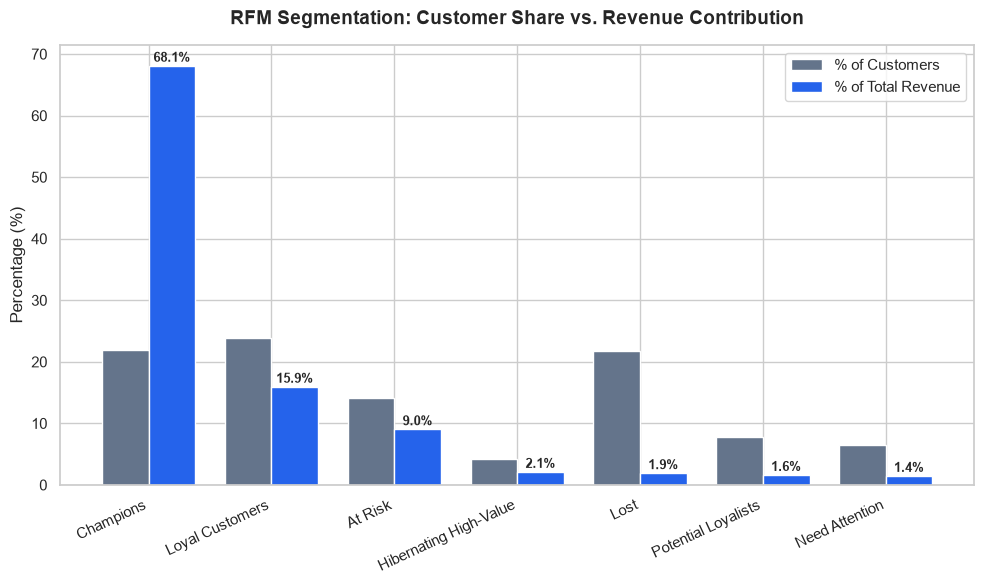

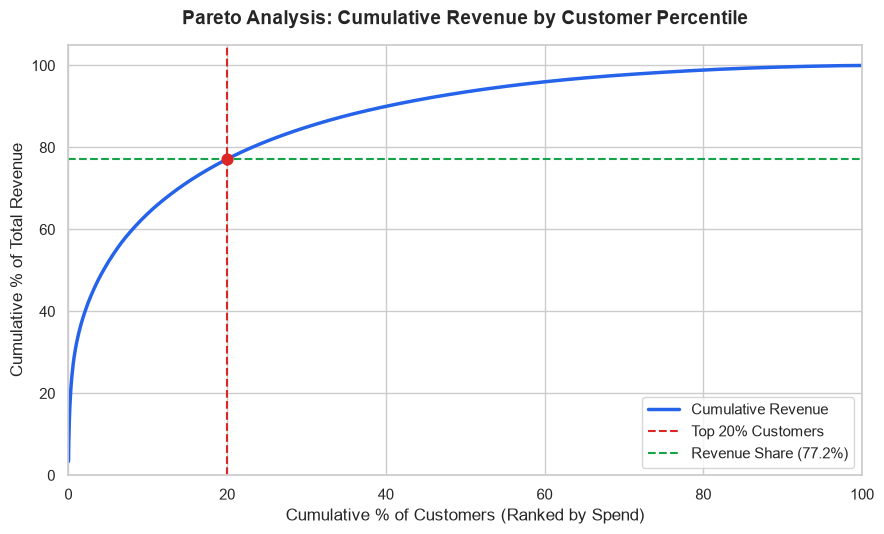

Saved charts to images/ and exported data/rfm_segments.csv


In [13]:
import os

os.makedirs("../images", exist_ok=True)
sns.set_theme(style="whitegrid")

# --- CHART 1: Customer Share vs. Revenue Share by RFM Segment ---
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(segment_summary))
width = 0.38

bars1 = ax.bar(x - width/2, segment_summary["customer_share_pct"], width, label="% of Customers", color="#64748b")
bars2 = ax.bar(x + width/2, segment_summary["revenue_share_pct"], width, label="% of Total Revenue", color="#2563eb")

ax.set_title("RFM Segmentation: Customer Share vs. Revenue Contribution", fontsize=14, fontweight="bold", pad=15)
ax.set_ylabel("Percentage (%)")
ax.set_xticks(x)
ax.set_xticklabels(segment_summary["segment"], rotation=25, ha="right")
ax.legend()

for bar in bars2:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("../../images/rfm_segment_revenue.png", dpi=300)
plt.show()

# --- CHART 2: Cumulative Revenue Curve (Pareto 80/20 Analysis) ---
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(rfm_sorted["cum_customers_pct"], rfm_sorted["cum_revenue_pct"], color="#2563eb", linewidth=2.5, label="Cumulative Revenue")
ax.axvline(20, color="#dc2626", linestyle="--", linewidth=1.5, label="Top 20% Customers")
ax.axhline(pareto_rev_share, color="#16a34a", linestyle="--", linewidth=1.5, label=f"Revenue Share ({pareto_rev_share:.1f}%)")
ax.scatter([20], [pareto_rev_share], color="#dc2626", zorder=5, s=60)

ax.set_title("Pareto Analysis: Cumulative Revenue by Customer Percentile", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Cumulative % of Customers (Ranked by Spend)")
ax.set_ylabel("Cumulative % of Total Revenue")
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("../../images/pareto_clv_curve.png", dpi=300)
plt.show()

# --- EXPORT CSV FOR TABLEAU PUBLIC (STEP 7) ---
rfm.to_csv("../data/rfm_segments.csv", index=False)
print("Saved charts to images/ and exported data/rfm_segments.csv")